#### name: Alaa Ajlan

#### ID: 445013493

#### group: 2

### import necessary libraries

In [269]:
#Data Handling
import pandas as pd          
          
# Data Preprocessing 
from sklearn.preprocessing import StandardScaler, OneHotEncoder , LabelEncoder 
from sklearn.compose import ColumnTransformer                    
          

#Models 
from sklearn.linear_model import LogisticRegression   
from sklearn.naive_bayes import GaussianNB, BernoulliNB 
from sklearn.model_selection import train_test_split             


#Evaluation
from sklearn.metrics import  accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay


#Visualization
import matplotlib.pyplot as plt  
from sklearn.metrics import roc_curve, auc

# **Breast Cancer Data**

### Step 1: Data Preprocessing 

### Lode the dataset

In [272]:
# Define column names for the dataset 
columns = ["ID","Diagnosis","radius_mean","texture_mean","perimeter_mean","area_mean",
       "smoothness_mean","compactness_mean","concavity_mean","concave_points_mean",
    "symmetry_mean","fractal_dimension_mean","radius_se","texture_se","perimeter_se",
        "area_se","smoothness_se","compactness_se","concavity_se","concave_points_se",
        "symmetry_se","fractal_dimension_se","radius_worst","texture_worst","perimeter_worst",
        "area_worst","smoothness_worst","compactness_worst","concavity_worst",
        "concave_points_worst","symmetry_worst","fractal_dimension_worst"]              

In [273]:
# red the data
cancer = pd.read_csv('wdbc.data' ,header=None, names=columns)


In [274]:
# show first 5 rows of the dataset
cancer.head()

,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


#### handling missing values

In [276]:
# Check for missing (null) values in each column of the dataset
cancer.isnull().sum() 

ID                         0
Diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

##### there are no missing value

#### Standardization

In [279]:
#show summary statistics
cancer.describe()

,ID,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500



#### The dataset shows large differences in the ranges of features.  
#### For example:  
- The column **perimeter_mean** has a mean of 91.96 and a std of 24.29  
- The column **texture_mean** has a mean of 19.28 and a std of 4.30  
#### Therefore, we need **Standardization** 

 Because standardization is applied only to numerical features, I split the data into features and target before applying it.

In [282]:
# Splitting Features and Target 
X_cancer = cancer.drop(["Diagnosis", "ID" ], axis=1) # Drop target and ID columns to keep only features  
Y_cancer = cancer ["Diagnosis"].map({"M":1, "B":0})   # Convert diagnosis labels: M : 1 (malignant), B : 0 (benign)

I split the data into training and testing sets before standardization to avoid data leakage. This way, the StandardScaler learns only from the training data and is not influenced by the test data, making the evaluation more accurate and realistic.
#### Train-Test Data Splitting

In [284]:
# Split data into 70% training and 30% testing sets
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cancer, Y_cancer, test_size=0.3, random_state=42, stratify=Y_cancer)


In [285]:
Standar = StandardScaler()  # Create a scaler for feature standardization (mean=0, std=1)

Xc_train_Standar = Standar.fit_transform(Xc_train)  # Fit on training data and standardize it
Xc_test_Standar = Standar.transform(Xc_test)        # Apply the same standardization to test data



### Step 2: Modl Building
#### Train Logistic Regression Model

In [287]:
# buld Logistic Regression model
log_model = LogisticRegression() 

# Training the model 
log_model.fit(Xc_train_Standar, yc_train)       

LogisticRegression()

#### Gaussian Naive Bayes Model
I used Gaussian Naive Bayes because all the features are numeric

In [289]:
gnb_model = GaussianNB()       # Init Gaussian Naive Bayes
gnb_model.fit(Xc_train_Standar, yc_train)  # Train model

GaussianNB()

#### Predictions


In [291]:
# B : 0, M : 1

y_pred_logistic = log_model.predict(Xc_test_Standar)  # Predict test labels with Logistic Regression
y_pred_gnb = gnb_model.predict(Xc_test_Standar)       # Predict test labels with Gaussian NB

print("Logistic Predictions:", y_pred_logistic)
print("\nGNB Predictions:", y_pred_gnb)

Logistic Predictions: [0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 1 1 1 0 1 0 0 1 1 1 0 1 1 0 0 1 0 0 1
 1 0 1 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 0 0 0 0 0
 1 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 1 1 1 1 0 0 0 0 0 1 1 0 1 0 1 1 0 1 0
 1 0 0 1 0 0 1 0 0 1 1 0 1 0 1 0 0 1 1 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 1 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1]

GNB Predictions: [0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 1 1 1 0 1 0 0 1 1 1 0 0 1 0 0 1 0 0 1
 1 0 1 1 0 1 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 0 0
 1 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 1 1 1 0 0 0 0 0 1 1 0 1 0 1 1 0 1 0
 1 0 0 1 0 0 1 0 0 1 1 0 1 0 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0
 0 1 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1]


### Step 3 : model evaluation and visualization


In [293]:
target_names = ['Benign (0)', 'Malignant (1)']  # Define class labels

# Logistic Regression evaluation
print("\nLogistic Regression")

#Evaluation Metrics
accuracy = accuracy_score(yc_test, y_pred_logistic)  
precision = precision_score(yc_test, y_pred_logistic) 
recall = recall_score(yc_test, y_pred_logistic)       
f1 = f1_score(yc_test, y_pred_logistic)              
y_proba_logistic = log_model.predict_proba(Xc_test_Standar)[:, 1]  # Probabilities for ROC
roc_auc = roc_auc_score(yc_test, y_proba_logistic)   

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}")
print("\n")




Logistic Regression
Accuracy: 0.9708
Precision: 0.9836
Recall: 0.9375
F1-Score: 0.9600
ROC-AUC Score: 0.9975




In [294]:
# Gaussian Naive Bayes evaluation
print("\nGaussian Naive Bayes")

#Evaluation Metrics
accuracy = accuracy_score(yc_test, y_pred_gnb)      
precision = precision_score(yc_test, y_pred_gnb)    
recall = recall_score(yc_test, y_pred_gnb)          
f1 = f1_score(yc_test, y_pred_gnb)                
y_proba_gnb = gnb_model.predict_proba(Xc_test_Standar)[:, 1]  # Probabilities for ROC
roc_auc = roc_auc_score(yc_test, y_proba_gnb)       

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}")


Gaussian Naive Bayes
Accuracy: 0.9357
Precision: 0.9492
Recall: 0.8750
F1-Score: 0.9106
ROC-AUC Score: 0.9933


### ROC Curve

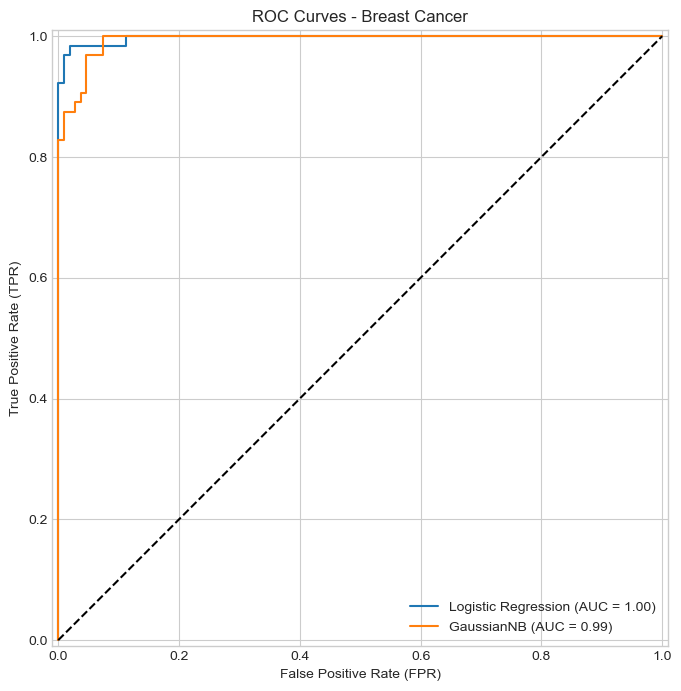

In [296]:
fig, ax = plt.subplots(figsize=(10, 8))
plt.style.use('seaborn-v0_8-whitegrid')


# Plot ROC curve for Logistic Regression
RocCurveDisplay.from_estimator(
    log_model, Xc_test_Standar, yc_test, 
    name="Logistic Regression",
    ax=ax)

# Plot ROC curve for Gaussian Naive Bayes
RocCurveDisplay.from_estimator(
    gnb_model, Xc_test_Standar, yc_test, 
    name="GaussianNB",
    ax=ax)

plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curves - Breast Cancer")
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Confusion Matrix

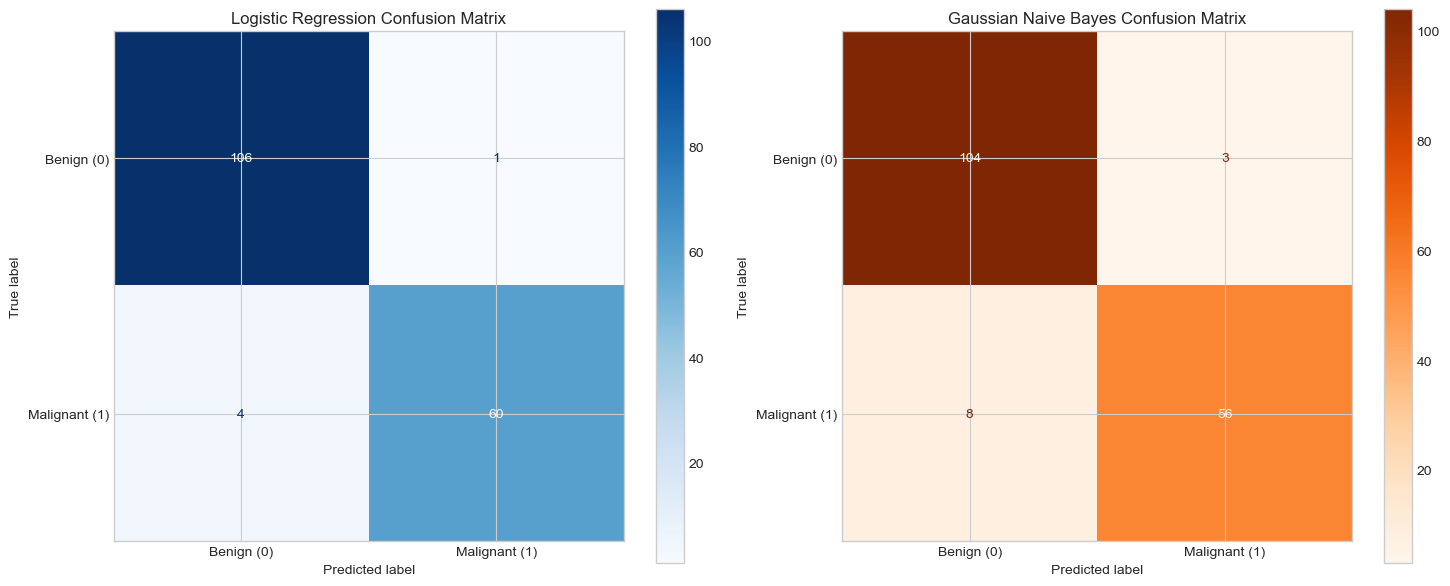

In [298]:
class_names = ['Benign (0)', 'Malignant (1)']


fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Confusion matrix for Logistic Regression
cm_display_lr = ConfusionMatrixDisplay.from_predictions(
    yc_test, y_pred_logistic, display_labels=class_names, ax=axes[0], cmap='Blues')
axes[0].set_title("Logistic Regression Confusion Matrix")

# Confusion matrix for Gaussian Naive Bayes
cm_display_gnb = ConfusionMatrixDisplay.from_predictions(
    yc_test, y_pred_gnb, display_labels=class_names, ax=axes[1], cmap='Oranges')
axes[1].set_title("Gaussian Naive Bayes Confusion Matrix")

plt.tight_layout()
plt.show()

#### Step 4: Comparative Analysis

1. **Compare the performance of Logistic Regression vs. Naive Bayes on each dataset.**
   
The Logistic Regression model generally performed better, achieving an accuracy of 0.97, while the Gaussian Naïve Bayes reached 0.93, which is still good but slightly lower.
For precision, Logistic Regression scored 0.98, indicating it made very few false positive (FP) errors. Gaussian Naïve Bayes scored 0.94, meaning it made some incorrect positive predictions.
In recall, Logistic Regression (0.93) also outperformed Gaussian Naïve Bayes (0.87), meaning it missed fewer actual positive cases (false negatives – FN).
Overall, Logistic Regression showed more balanced and consistent performance across all metrics

2. **Discuss how dataset characteristics (feature types, distributions) influenced results.**

The Breast Cancer dataset contains all continuous features. Most of these features follow a distribution close to normal.

Impact on Logistic Regression : 
It performs well with numeric data, especially after standardization, which improves its accuracy.
Impact on Gaussian Naïve Bayes:
This model assumes feature independence and a normal distribution, but correlations between some features reduce its performance compared to Logistic Regression.
n.ics

3. **Explore how preprocessing choices affected model performance.**

In the data, there was a large difference in feature values, so standardization was very important. This step made all features on the same scale, helping the model learn faster and achieve more accurate results

4. **Reflect on which model you would recommend for each dataset and why.**

I recommend the Logistic Regression model because it provides higher performance and fits the data better, while theGaussian Naïve Bayes assumes a normal distribution, which is not fully satisfied in this dataset. Additionally, Logistic Regression showed better results across all important metrics, especially F1-Score and Recall, making it the safer and more reliable choice, particularly in medical contexts such as breast cancer diagnosis.

# **Adult Data**

### Step 1: Data Preprocessing 

### Lode the dataset

In [304]:
# Define column names for the Adult dataset
adult_columns = [ "age", "workclass", "fnlwgt", "education", "education-num", "marital-status", 
                 "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss", 
                 "hours-per-week", "native-country", "income" ]

In [305]:
# red the data and assign column names
adult = pd.read_csv('adult.data', header=None, names=adult_columns,na_values=" ?", skipinitialspace=True)

In [306]:
# Print the first 5 rows
adult.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### Checking Missing Values

In [308]:
# Check for missing (null) values in each column of the dataset
print(adult.isnull().sum())

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


The data appeared to have no missing values, but the data source indicated that some values are missing.
This means the values are not null, but they are incomplete or invalid.

In [310]:
# Check the unique values 
for col in ['workclass', 'occupation', 'native-country']:
    print(f"{col} unique values:\n{adult[col].unique()}\n")


workclass unique values:
['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov' '?'
 'Self-emp-inc' 'Without-pay' 'Never-worked']

occupation unique values:
['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' '?'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']

native-country unique values:
['United-States' 'Cuba' 'Jamaica' 'India' '?' 'Mexico' 'South'
 'Puerto-Rico' 'Honduras' 'England' 'Canada' 'Germany' 'Iran'
 'Philippines' 'Italy' 'Poland' 'Columbia' 'Cambodia' 'Thailand' 'Ecuador'
 'Laos' 'Taiwan' 'Haiti' 'Portugal' 'Dominican-Republic' 'El-Salvador'
 'France' 'Guatemala' 'China' 'Japan' 'Yugoslavia' 'Peru'
 'Outlying-US(Guam-USVI-etc)' 'Scotland' 'Trinadad&Tobago' 'Greece'
 'Nicaragua' 'Vietnam' 'Hong' 'Ireland' 'Hungary' 'Holand-Netherlands']



**Some entries in the dataset use ? to represent missing or unknown values.**

In [312]:
# Replace '?' in selected categorical columns with the mode of each column
cols_to_fix = ['workclass', 'occupation', 'native-country']
replace_dict = {col: adult[col].mode()[0] for col in cols_to_fix}
adult[cols_to_fix] = adult[cols_to_fix].replace('?', replace_dict)


In [313]:
# Check again the unique values
for col in ['workclass', 'occupation', 'native-country']:
    print(f"{col} unique values:\n{adult[col].unique()}\n")


workclass unique values:
['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov'
 'Self-emp-inc' 'Without-pay' 'Never-worked']

occupation unique values:
['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' 'Protective-serv'
 'Armed-Forces' 'Priv-house-serv']

native-country unique values:
['United-States' 'Cuba' 'Jamaica' 'India' 'Mexico' 'South' 'Puerto-Rico'
 'Honduras' 'England' 'Canada' 'Germany' 'Iran' 'Philippines' 'Italy'
 'Poland' 'Columbia' 'Cambodia' 'Thailand' 'Ecuador' 'Laos' 'Taiwan'
 'Haiti' 'Portugal' 'Dominican-Republic' 'El-Salvador' 'France'
 'Guatemala' 'China' 'Japan' 'Yugoslavia' 'Peru'
 'Outlying-US(Guam-USVI-etc)' 'Scotland' 'Trinadad&Tobago' 'Greece'
 'Nicaragua' 'Vietnam' 'Hong' 'Ireland' 'Hungary' 'Holand-Netherlands']



 **All '?' values have been replaced, no missing entries remain**

### Data Encoding

In [316]:
# Encode 'sex' column (binary)
le = LabelEncoder()
adult['sex'] = le.fit_transform(adult['sex'])

# One-Hot encode other categorical columns
categorical_cols = ['workclass', 'education', 'marital-status', 'occupation',
                    'relationship', 'race', 'native-country']
Eadult = pd.get_dummies(adult, columns=categorical_cols, dtype=int)

In [317]:
# Show the first 5 rows
Eadult.head()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,income,workclass_Federal-gov,workclass_Local-gov,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,77516,13,1,2174,0,40,<=50K,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,83311,13,1,0,0,13,<=50K,0,0,...,0,0,0,0,0,0,0,1,0,0
2,38,215646,9,1,0,0,40,<=50K,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,234721,7,1,0,0,40,<=50K,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,338409,13,0,0,0,40,<=50K,0,0,...,0,0,0,0,0,0,0,0,0,0


#### Standardization

In [319]:
# Show statistical summary
Eadult.describe()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,...,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,0.669205,1077.648844,87.303830,40.437456,0.029483,0.064279,0.000215,...,0.001136,0.003501,0.000369,0.002457,0.001566,0.000553,0.000584,0.913762,0.002058,0.000491
std,13.640433,1.055500e+05,2.572720,0.470506,7385.292085,402.960219,12.347429,0.169159,0.245254,0.014661,...,0.033691,0.059068,0.019194,0.049507,0.039546,0.023506,0.024149,0.280720,0.045316,0.022162
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,0.000000,40.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,37.000000,1.783560e+05,10.000000,1.000000,0.000000,0.000000,40.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,48.000000,2.370510e+05,12.000000,1.000000,0.000000,0.000000,45.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,90.000000,1.484705e+06,16.000000,1.000000,99999.000000,4356.000000,99.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


#### The dataset shows large differences in the ranges of features.  
#### For example:  
- The column **education-num** has a mean of 10.08 and a std of 2.57 
- The column **capital-gain** has a mean of 1077.64 and a std of 7385.29
#### Therefore, we need **Standardization** 

 Because standardization is applied only to numerical features, I split the data into features and target before applying it.

### Splitting Features and Target

In [323]:
X_adult = Eadult.drop("income", axis=1) # Drop target column to keep only features

Y_adult = Eadult["income"].map({'<=50K': 0, '>50K': 1})  # Convert income labels to 0 (<=50K) and 1 (>50K)

I split the data into training and testing sets before standardization to avoid data leakage. This way, the StandardScaler learns only from the training data and is not influenced by the test data, making the evaluation more accurate and realistic.
#### Train-Test Data Splitting

In [325]:
# Split data into 70% training and 30% testing sets
X_train, X_test, Y_train, Y_test = train_test_split(
    X_adult, Y_adult, test_size=0.3, random_state=42, stratify=Y_adult
)


In [326]:
 # Create a scaler for feature standardization (mean=0, std=1)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 2 : Model Building

### Logistic Regression Model

In [329]:
# buld Logistic Regression model
log_adult_model = LogisticRegression()

# Train model
log_adult_model.fit(X_train_scaled, Y_train) 

LogisticRegression()

### Gaussian Naive Bayes Model

In [331]:
# Build Gaussian Naive Bayes model
gnb_adult_model = GaussianNB()  

# Train model
gnb_adult_model.fit(X_train_scaled, Y_train)  


GaussianNB()

In [332]:
# Build Bernoulli Naive Bayes model
ber_model = BernoulliNB()

# Train model
ber_model.fit(X_train, Y_train)

BernoulliNB()

### Prediction

In [334]:
y_pred_log_adult = log_adult_model.predict(X_test_scaled)  # Logistic predictions
y_pred_gnb_adult = gnb_adult_model.predict(X_test_scaled)  # GNB predictions
y_pred_ber = ber_model.predict(X_test)  #Bernoulli predictions


# Get predicted probabilities
y_probs_log_adult = log_adult_model.predict_proba(X_test_scaled)[:, 1]
y_probs_gnb_adult = gnb_adult_model.predict_proba(X_test_scaled)[:, 1]
y_probs_ber = ber_model.predict_proba(X_test)[:, 1]

print("Logistic Regression")
print("Predictions:\n", y_pred_log_adult)
print("Probabilities:\n", y_probs_log_adult)

print("\nGaussian Naive Bayes")
print("Predictions:\n", y_pred_gnb_adult)
print("Probabilities:\n", y_probs_gnb_adult)

print("\nBernoulli Naive Bayes")
print("Predictions:\n", y_pred_ber)
print("Probabilities:\n", y_probs_ber)


Logistic Regression
Predictions:
 [0 0 0 ... 1 1 0]
Probabilities:
 [0.39446319 0.15569287 0.10349931 ... 0.59721231 0.88811321 0.00391802]

Gaussian Naive Bayes
Predictions:
 [1 1 1 ... 1 1 1]
Probabilities:
 [1. 1. 1. ... 1. 1. 1.]

Bernoulli Naive Bayes
Predictions:
 [1 0 0 ... 1 1 0]
Probabilities:
 [8.28709656e-01 2.33221979e-01 1.81133340e-02 ... 9.75768305e-01
 9.84899490e-01 6.62928738e-05]


### Step 3: Model Evaluation and Visualization

In [336]:
# Define class labels for Adult dataset
target_names_adult = ['<=50K (0)', '>50K (1)']

# Logistic Regression evaluation
print("Logistic Regression")

#Evaluation Metrics
accuracy_log = accuracy_score(Y_test, y_pred_log_adult)
precision_log = precision_score(Y_test, y_pred_log_adult)
recall_log = recall_score(Y_test, y_pred_log_adult)
f1_log = f1_score(Y_test, y_pred_log_adult)
y_probs_log_adult = log_adult_model.predict_proba(X_test_scaled)[:, 1]
roc_auc_log = roc_auc_score(Y_test, y_probs_log_adult)

print("Accuracy:", accuracy_log)
print("Precision:", precision_log)
print("Recall:", recall_log)
print("F1 Score:", f1_log)
print("ROC-AUC Score:", roc_auc_log)


Logistic Regression
Accuracy: 0.8546422356433616
Precision: 0.7384851586489253
Recall: 0.6135204081632653
F1 Score: 0.6702275894101254
ROC-AUC Score: 0.906633409734394


### Confusion Matrix

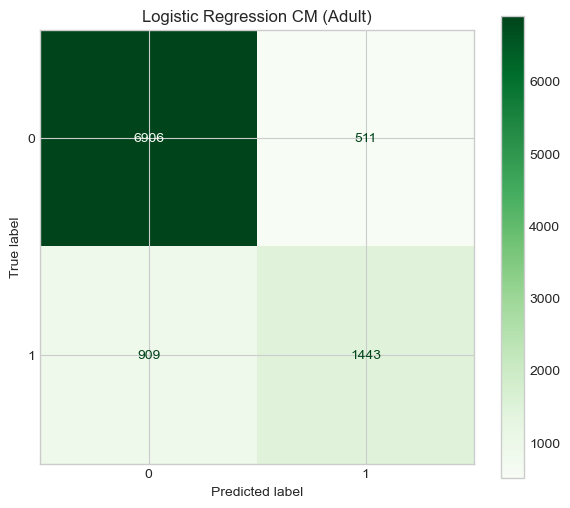

In [338]:
# Confusion matrix for Logistic Regression
fig, ax = plt.subplots(figsize=(7,6))

ConfusionMatrixDisplay.from_predictions(
    Y_test, y_pred_log_adult, display_labels=[0,1], ax=ax, cmap='Greens')

ax.set_title("Logistic Regression CM (Adult)")
plt.show()

In [339]:
# Gaussian Naive Bayes evaluation
print("\nGaussian Naive Bayes")

#Evaluation Metrics
accuracy_gnb = accuracy_score(Y_test, y_pred_gnb_adult)
precision_gnb = precision_score(Y_test, y_pred_gnb_adult)
recall_gnb = recall_score(Y_test, y_pred_gnb_adult)
f1_gnb = f1_score(Y_test, y_pred_gnb_adult)
y_probs_gnb_adult = gnb_adult_model.predict_proba(X_test_scaled)[:, 1]
roc_auc_gnb = roc_auc_score(Y_test, y_probs_gnb_adult)     


print("Accuracy:", accuracy_gnb)
print("Precision:", precision_gnb)
print("Recall:", recall_gnb)
print("F1 Score:", f1_gnb)
print("ROC-AUC Score:", roc_auc_gnb)


Gaussian Naive Bayes
Accuracy: 0.37332377930187327
Precision: 0.27452153110047844
Recall: 0.9757653061224489
F1 Score: 0.42849141150112025
ROC-AUC Score: 0.6575324750366642


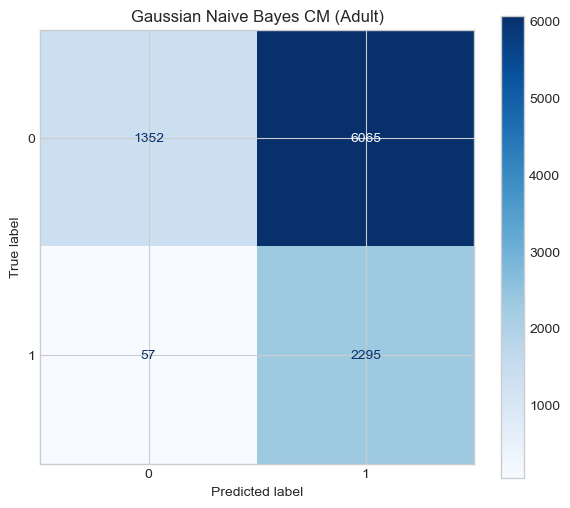

In [340]:
# Confusion matrix for Gaussian Naive Bayes
fig, ax = plt.subplots(figsize=(7,6))

ConfusionMatrixDisplay.from_predictions(
    Y_test, y_pred_gnb_adult, display_labels=[0,1], ax=ax, cmap='Blues')

ax.set_title("Gaussian Naive Bayes CM (Adult)")
plt.show()


In [341]:
#Bernoulli Naive Bayes evaluation
print("Bernoulli NB Metrics:")

#Evaluation Metrics
accuracy_ber = accuracy_score(Y_test, y_pred_ber)
precision_ber = precision_score(Y_test, y_pred_ber)
recall_ber = recall_score(Y_test, y_pred_ber)
f1_ber = f1_score(Y_test, y_pred_ber)
y_probs_ber = ber_model.predict_proba(X_test)[:, 1]
roc_auc_ber = roc_auc_score(Y_test, y_probs_ber)

print("Accuracy:", accuracy_ber)
print("Precision:", precision_ber)
print("Recall:", recall_ber)
print("F1 Score:", f1_ber)
print("ROC-AUC Score:", roc_auc_ber)


Bernoulli NB Metrics:
Accuracy: 0.7645613675913604
Precision: 0.5069630423138726
Recall: 0.8048469387755102
F1 Score: 0.6220834702596122
ROC-AUC Score: 0.8689047110012942


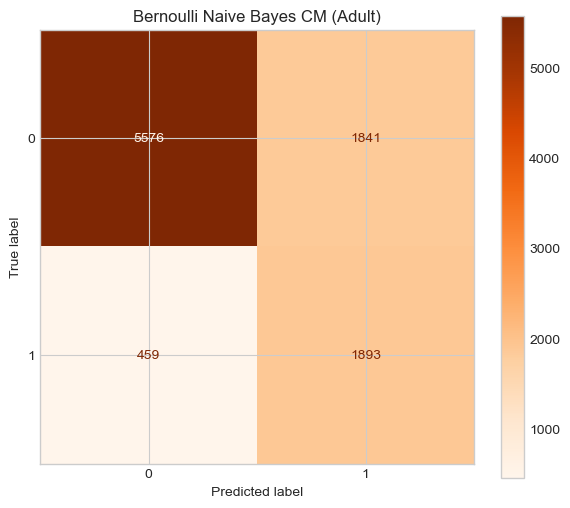

In [342]:
# Confusion matrix for Bernoulli Naive Bayes
fig, ax = plt.subplots(figsize=(7,6))

ConfusionMatrixDisplay.from_predictions(
    Y_test, y_pred_ber, display_labels=[0,1], ax=ax, cmap='Oranges'
)

ax.set_title("Bernoulli Naive Bayes CM (Adult)")
plt.show()

### ROC Curve

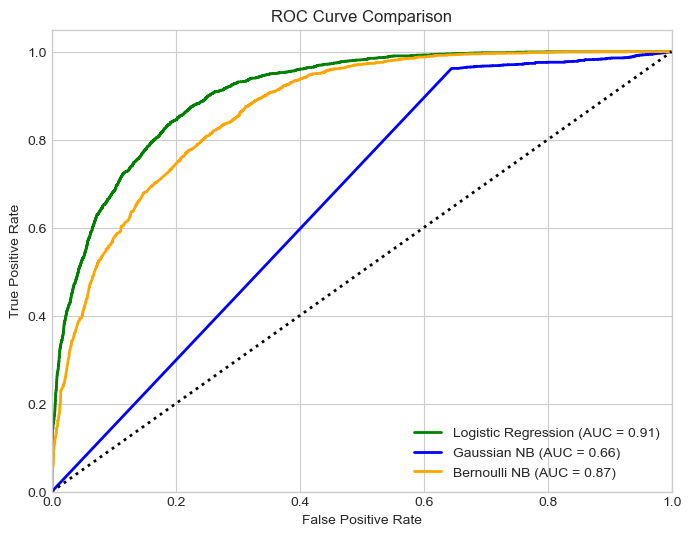

In [344]:
plt.figure(figsize=(8,6))

# Logistic Regression
fpr_log, tpr_log, _ = roc_curve(Y_test, y_probs_log_adult, pos_label=1)
roc_auc_log = auc(fpr_log, tpr_log)
plt.plot(fpr_log, tpr_log, color='green', linestyle='-', linewidth=2,
         label=f'Logistic Regression (AUC = {roc_auc_log:.2f})')

# Gaussian NB
fpr_gnb, tpr_gnb, _ = roc_curve(Y_test, y_probs_gnb_adult, pos_label=1)
roc_auc_gnb = auc(fpr_gnb, tpr_gnb)
plt.plot(fpr_gnb, tpr_gnb, color='blue', linestyle='-', linewidth=2,
         label=f'Gaussian NB (AUC = {roc_auc_gnb:.2f})')

# Bernoulli NB
fpr_bnb, tpr_bnb, _ = roc_curve(Y_test, y_probs_ber, pos_label=1)
roc_auc_bnb = auc(fpr_bnb, tpr_bnb)
plt.plot(fpr_bnb, tpr_bnb, color='orange', linestyle='-', linewidth=2,
         label=f'Bernoulli NB (AUC = {roc_auc_bnb:.2f})')

plt.plot([0,1], [0,1], color='black', linestyle=':', linewidth=2, label="_nolegend_")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


#### Step 4: Comparative Analysis**

1. **Compare the performance of Logistic Regression vs. Naive Bayes on each dataset.**
Logistic Regression achieved the highest scores across all metrics because it can handle both numerical and categorical data effectively. For Naïve Bayes, the Bernoulli model is suitable for categorical data after converting it to binary values, while the Gaussian model works well with numerical data. However, in this case, the data did not fully meet Gaussian’s assumptions, which led to its weaker performance.

**2. Discuss how dataset characteristics (feature types, distributions) influenced results**. 
Naive Bayes models showed poor performance due to the mixture of numerical and categorical features in the dataset.

**3. Explore how preprocessing choices affected model performance.** 
The most important preprocessing step was One-Hot Encoding for categorical features, because models cannot handle them directly

**4. Reflect on which model you would recommend for each dataset and why**.
I recommend using the Logistic Regression model because it effectively handles all types of features, whether numerical or categorical.